In [1]:
import re
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

In [3]:
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Respons Topik 2 – Kebiasaan Digital – 3 TI A.xlsx to Respons Topik 2 – Kebiasaan Digital – 3 TI A.xlsx
File terbaca: Respons Topik 2 – Kebiasaan Digital – 3 TI A.xlsx


In [4]:
JUMLAH_KOLOM_DEMOGRAFI = 2

df = pd.read_excel(nama_file)
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]

print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Jumlah responden : 39
Jumlah butir     : 15
Data kosong      : 0


In [5]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


/tmp/ipykernel_2646/2502456638.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")


,Kebiasaan penggunaan teknologi digital [TD1. Saya membuka media sosial ketika sedang mengerjakan tugas kuliah.],Kebiasaan penggunaan teknologi digital [TD2. Saya memeriksa notifikasi ponsel ketika sedang mengerjakan tugas kuliah.],Kebiasaan penggunaan teknologi digital [TD3. Saya meninggalkan sementara pengerjaan tugas kuliah untuk mengakses hiburan di gadget.],Kebiasaan penggunaan teknologi digital [TD4. Saya membuka konten hiburan sambil menggunakan AI untuk mengerjakan tugas kuliah.],Kebiasaan penggunaan teknologi digital [TD5. Saya beralih ke aplikasi lain sebelum selesai membaca jawaban AI untuk tugas kuliah.],Kebiasaan penggunaan teknologi digital [TD6. Saya menggunakan jawaban AI dalam tugas kuliah setelah membacanya sekilas.],Prokrastinasi akademik [PA1. Saya menunda memulai tugas kuliah hingga mendekati batas pengumpulan.],Prokrastinasi akademik [PA2. Saya memulai pengerjaan tugas kuliah lebih lambat daripada waktu yang saya rencanakan.],Prokrastinasi akademik [PA3. Saya menunda melanjutkan tugas kuliah yang sudah saya mulai.],Prokrastinasi akademik [PA4. Saya menyelesaikan tugas kuliah pada saat waktu pengumpulan hampir berakhir.],Respons emosional [RE1. Saya merasa tertekan ketika waktu pengerjaan tugas menjadi singkat akibat menunda.],Respons emosional [RE2. Saya merasa cemas ketika tugas yang saya tunda mendekati batas pengumpulan.],Respons emosional [RE3. Saya merasa panik ketika beberapa tugas yang saya tunda harus segera dikumpulkan.],Respons emosional [RE4. Saya merasa gelisah ketika memikirkan tugas yang pengerjaannya saya tunda.],Respons emosional [RE5. Saya merasa kewalahan menghadapi tugas yang menumpuk akibat penundaan.]
0,1,2,1,3,4,2,1,5,2,4,1,4,1,2,2
1,4,3,5,3,2,3,3,2,3,2,4,3,4,3,4
2,5,4,3,4,3,5,2,4,5,1,4,5,2,1,5
3,1,2,1,1,1,2,1,2,1,1,5,4,5,4,5
4,5,4,5,4,5,4,4,5,4,5,5,4,5,3,4


In [6]:
dimensi = {}
for kolom in butir.columns:
    nama = re.match(r"^(.*?) \[", kolom).group(1).strip()
    dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respons emosional: 5 butir


In [7]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 39 | r tabel (α=0,05; df=37) = 0.316


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Kebiasaan penggunaan teknologi digital,B1,0.530,0.169,0.0005,Valid
1,Kebiasaan penggunaan teknologi digital,B2,0.592,0.346,0.0001,Valid
2,Kebiasaan penggunaan teknologi digital,B3,0.509,0.224,0.0009,Valid
3,Kebiasaan penggunaan teknologi digital,B4,0.410,0.084,0.0095,Valid
4,Kebiasaan penggunaan teknologi digital,B5,0.448,0.150,0.0042,Valid
5,Kebiasaan penggunaan teknologi digital,B6,0.593,0.328,0.0001,Valid
6,Prokrastinasi akademik,B1,0.490,0.079,0.0015,Valid
7,Prokrastinasi akademik,B2,0.609,0.279,0.0000,Valid
8,Prokrastinasi akademik,B3,0.637,0.289,0.0000,Valid
9,Prokrastinasi akademik,B4,0.606,0.127,0.0000,Valid


In [8]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a),
    })
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Kebiasaan penggunaan teknologi digital,6,0.433,Tidak reliabel
1,Prokrastinasi akademik,4,0.349,Tidak reliabel
2,Respons emosional,5,0.311,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Kebiasaan penggunaan teknologi digital,B1,0.420
1,Kebiasaan penggunaan teknologi digital,B2,0.314
2,Kebiasaan penggunaan teknologi digital,B3,0.381
3,Kebiasaan penggunaan teknologi digital,B4,0.462
4,Kebiasaan penggunaan teknologi digital,B5,0.422
5,Kebiasaan penggunaan teknologi digital,B6,0.319
6,Prokrastinasi akademik,B1,0.400
7,Prokrastinasi akademik,B2,0.192
8,Prokrastinasi akademik,B3,0.170
9,Prokrastinasi akademik,B4,0.370


,Dimensi / Butir,Mean,Median,Std Dev (SD),Skewness,Kurtosis
0,[TOTAL DIMENSI] Kebiasaan penggunaan teknologi...,17.846,18.0,4.481,-0.093,0.368
1,Kebiasaan penggunaan teknologi digital - B1,2.769,2.0,1.724,0.247,-1.741
2,Kebiasaan penggunaan teknologi digital - B2,3.205,3.0,1.321,-0.038,-1.375
3,Kebiasaan penggunaan teknologi digital - B3,3.000,3.0,1.395,-0.122,-1.285
4,Kebiasaan penggunaan teknologi digital - B4,3.231,3.0,1.495,-0.218,-1.401
5,Kebiasaan penggunaan teknologi digital - B5,2.667,2.0,1.402,0.273,-1.393
6,Kebiasaan penggunaan teknologi digital - B6,2.974,3.0,1.405,0.108,-1.417
7,[TOTAL DIMENSI] Prokrastinasi akademik,11.000,12.0,3.293,-0.089,0.100
8,Prokrastinasi akademik - B1,2.154,2.0,1.387,0.958,-0.395
9,Prokrastinasi akademik - B2,3.154,3.0,1.247,-0.049,-1.190


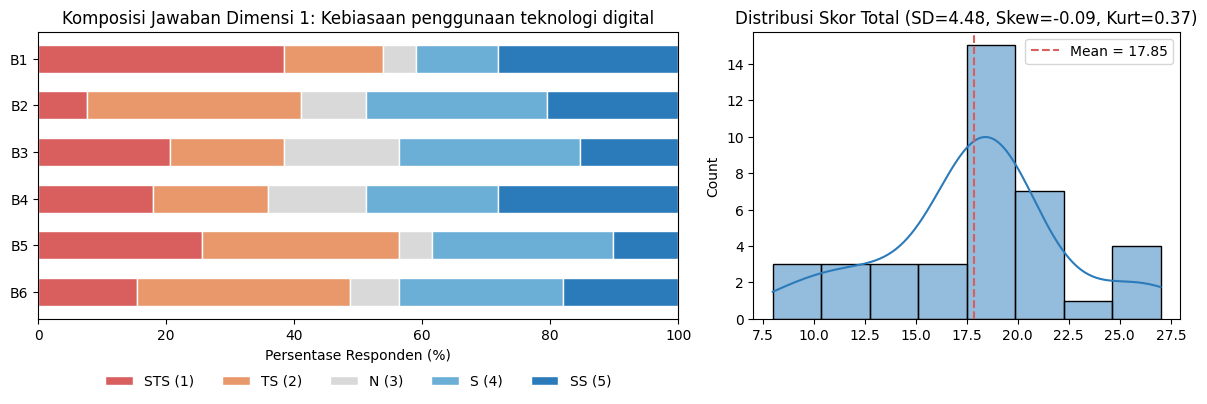

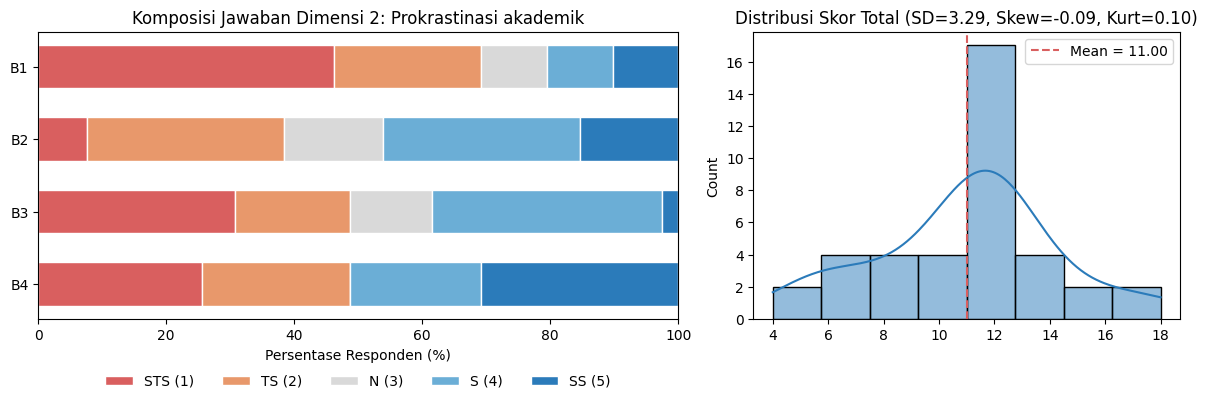

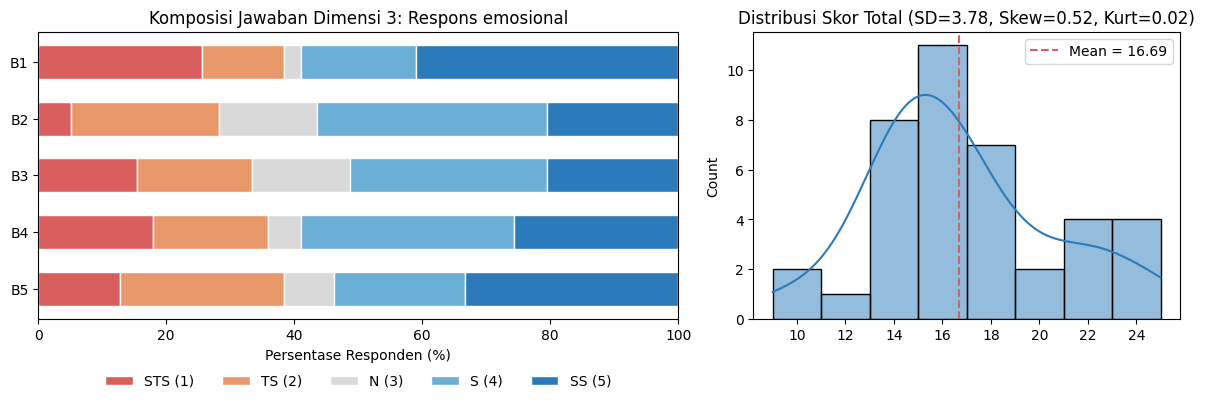

In [9]:
deskriptif_rows = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    skor_total = x.sum(axis=1)
    deskriptif_rows.append({
        "Dimensi / Butir": f"[TOTAL DIMENSI] {nama}",
        "Mean": round(skor_total.mean(), 3),
        "Median": round(skor_total.median(), 3),
        "Std Dev (SD)": round(skor_total.std(ddof=1), 3),
        "Skewness": round(skor_total.skew(), 3),
        "Kurtosis": round(skor_total.kurt(), 3),
    })
    for i, col in enumerate(daftar, 1):
        s = x[col]
        deskriptif_rows.append({
            "Dimensi / Butir": f"  {nama} - B{i}",
            "Mean": round(s.mean(), 3),
            "Median": round(s.median(), 3),
            "Std Dev (SD)": round(s.std(ddof=1), 3),
            "Skewness": round(s.skew(), 3),
            "Kurtosis": round(s.kurt(), 3),
        })

tabel_deskriptif = pd.DataFrame(deskriptif_rows)
display(tabel_deskriptif)

label_skala = ['STS (1)', 'TS (2)', 'N (3)', 'S (4)', 'SS (5)']
warna_skala = ['#d95f5f', '#e8986b', '#d9d9d9', '#6baed6', '#2b7bba']

for idx, (nama, daftar) in enumerate(dimensi.items(), 1):
    x = num[daftar]
    k_labels = [f'B{i}' for i in range(1, len(daftar)+1)]
    counts_df = pd.DataFrame(index=k_labels, columns=[1, 2, 3, 4, 5])
    for i, col in enumerate(daftar):
        counts_df.loc[k_labels[i]] = x[col].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0).values
    pct_df = counts_df.div(counts_df.sum(axis=1), axis=0) * 100

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.5, 1]})
    bottom = np.zeros(len(k_labels))
    for s_val, s_lbl, col_hex in zip([1, 2, 3, 4, 5], label_skala, warna_skala):
        vals = pct_df[s_val].values.astype(float)
        ax1.barh(k_labels, vals, left=bottom, label=s_lbl, color=col_hex, edgecolor='white', height=0.6)
        bottom += vals
    ax1.set_xlim(0, 100)
    ax1.invert_yaxis()
    ax1.set_xlabel('Persentase Responden (%)')
    ax1.set_title(f'Komposisi Jawaban Dimensi {idx}: {nama}')
    ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=5, frameon=False)

    skor_total = x.sum(axis=1)
    sns.histplot(skor_total, kde=True, ax=ax2, color='#2b7bba', bins=8)
    ax2.axvline(skor_total.mean(), color='#d95f5f', linestyle='--', label=f'Mean = {skor_total.mean():.2f}')
    ax2.set_title(f'Distribusi Skor Total (SD={skor_total.std(ddof=1):.2f}, Skew={skor_total.skew():.2f}, Kurt={skor_total.kurt():.2f})')
    ax2.legend()
    plt.tight_layout()
    plt.show()

In [10]:
hasil_perbaikan = []
for nama, daftar in dimensi.items():
    kolom_aktif = list(daftar)
    label_aktif = [f"B{i+1}" for i in range(len(daftar))]
    alpha_awal = cronbach_alpha(num[kolom_aktif])
    butir_dibuang = []
    while len(kolom_aktif) > 2:
        x_aktif = num[kolom_aktif]
        a_sekarang = cronbach_alpha(x_aktif)
        opsi_hapus = {i: cronbach_alpha(x_aktif.drop(columns=kolom_aktif[i])) for i in range(len(kolom_aktif))}
        idx_terbaik = max(opsi_hapus, key=opsi_hapus.get)
        if opsi_hapus[idx_terbaik] > a_sekarang:
            butir_dibuang.append(label_aktif.pop(idx_terbaik))
            kolom_aktif.pop(idx_terbaik)
        else:
            break
    alpha_akhir = cronbach_alpha(num[kolom_aktif])
    hasil_perbaikan.append({
        "Dimensi": nama,
        "Alpha Awal": round(alpha_awal, 3),
        "Butir Dibuang": ", ".join(butir_dibuang) if butir_dibuang else "-",
        "Butir Tersisa": ", ".join(label_aktif),
        "Alpha Setelah Perbaikan": round(alpha_akhir, 3),
        "Kategori Akhir": kategori(alpha_akhir)
    })

tabel_perbaikan = pd.DataFrame(hasil_perbaikan)
display(tabel_perbaikan)

gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")
with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)
    tabel_deskriptif.to_excel(w, sheet_name="Deskriptif", index=False)
    tabel_perbaikan.to_excel(w, sheet_name="Perbaikan_Instrumen", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")

,Dimensi,Alpha Awal,Butir Dibuang,Butir Tersisa,Alpha Setelah Perbaikan,Kategori Akhir
0,Kebiasaan penggunaan teknologi digital,0.433,"B4, B5, B3, B1","B2, B6",0.801,Baik
1,Prokrastinasi akademik,0.349,"B1, B3","B2, B4",0.416,Tidak reliabel
2,Respons emosional,0.311,"B4, B2, B1","B3, B5",0.681,Tidak reliabel


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>